In [1]:
import numpy as np
import joblib
import xarray as xr

In [9]:
data_base_dir_winter = "/work/bb1097/b383521/GW_Data/Data_set_ML/"
data_base_dir_summer = "/work/bb1097/b383521/GW_Data_Summer/Data_set_ML/"
tag = "ocean"
name = f"corsed_action_{tag}.pkl"
data_set_winter = joblib.load(data_base_dir_winter + name)
data_set_summer = joblib.load(data_base_dir_summer + name)
n_feture = data_set_summer["X_train"].shape[-1]
X_winter = data_set_winter["X_train"].reshape(-1, n_feture)
X_summer = data_set_summer["X_train"].reshape(-1, n_feture)


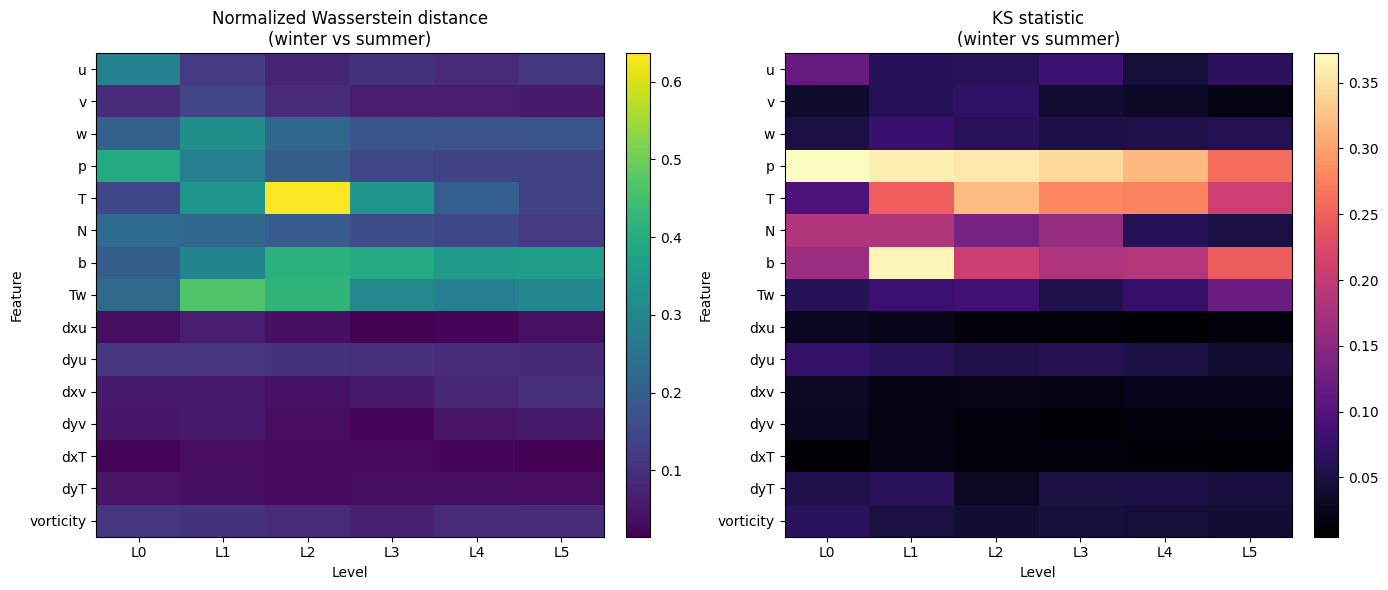

In [16]:
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance, ks_2samp
import numpy as np

n_features = 15
n_levels   = 6
assert n_feture == n_features * n_levels, "check n_features * n_levels matches your data"

feature_names =     keys = ["u", "v", "w", "p", "T", "N", "b", "Tw",
            "dxu", "dyu", "dxv", "dyv", "dxT", "dyT",
            "vorticity"]  # replace with real names if you have them
level_names   = [f"L{j}" for j in range(n_levels)]

# ---- Step 1: compute a shift metric for every (feature, level) pair ----
wass_matrix = np.zeros((n_features, n_levels))
ks_matrix   = np.zeros((n_features, n_levels))

for col in range(n_feture):
    f_idx = col // n_levels     # ASSUMES feature-major ordering — flip if wrong
    l_idx = col % n_levels

    w_col = X_winter[:, col]
    s_col = X_summer[:, col]
    w_col = w_col[~np.isnan(w_col)]
    s_col = s_col[~np.isnan(s_col)]

    # normalize wasserstein by winter's std so it's comparable across features with different scales
    std_w = w_col.std()
    wass_matrix[f_idx, l_idx] = wasserstein_distance(w_col, s_col) / (std_w + 1e-8)
    ks_matrix[f_idx, l_idx]   = ks_2samp(w_col, s_col).statistic

# ---- Step 2: heatmap of shift magnitude ----
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, mat, title, cmap in zip(
        axes, [wass_matrix, ks_matrix],
        ["Normalized Wasserstein distance\n(winter vs summer)", "KS statistic\n(winter vs summer)"],
        ["viridis", "magma"]):
    im = ax.imshow(mat, aspect="auto", cmap=cmap)
    ax.set_xticks(range(n_levels))
    ax.set_xticklabels(level_names)
    ax.set_yticks(range(n_features))
    ax.set_yticklabels(feature_names)
    ax.set_xlabel("Level")
    ax.set_ylabel("Feature")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()